# INSY 674 · Logistic Regression Modeling, Results and Interpretation

This notebook fits a logistic regression model to predict whether an online shopping session ends in a purchase (`Revenue = 1`). Logistic regression is the simplest model in our comparison and its coefficients are easy to interpret, so it serves as the linear baseline for Random Forest and XGBoost.

It uses the same train/test split, cross-validation folds and primary metric (average precision) as the other model notebooks. `PageValues` is left out of the main model because it may not be available before a purchase happens. Section 12 reports results with it included.

## 1 · Setup

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             make_scorer, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Hide convergence warnings from the saga solver during grid search
warnings.filterwarnings("ignore")

RANDOM_STATE = 42  # same seed as the EDA split and the RF notebook
TARGET = "Revenue"

# Tables, figures and the fitted models are all saved in one folder
OUT = Path("logistic_regression_results"); OUT.mkdir(exist_ok=True)
MODEL_DIR = OUT
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2 · Load the Train and Test Split

In [2]:
train_raw = pd.read_csv("train_raw.csv")
test_raw = pd.read_csv("test_raw.csv")

def to_bool(s):
    """Convert TRUE/FALSE (or 1/0) values to integers 1/0."""
    return s.astype(str).str.upper().map({"TRUE": 1, "FALSE": 0, "1": 1, "0": 0}).astype(int)

for d in (train_raw, test_raw):
    d[TARGET] = to_bool(d[TARGET])
    d["Weekend"] = to_bool(d["Weekend"])

print("train:", train_raw.shape, f"purchase rate {train_raw[TARGET].mean():.4%}")
print("test: ", test_raw.shape, f"purchase rate {test_raw[TARGET].mean():.4%}")

train: (9764, 19) purchase rate 15.6288%
test:  (2441, 19) purchase rate 15.6493%


The training set has **9,764 sessions** and the test set **2,441**. Purchases make up **15.63%** of training sessions and **15.65%** of test sessions, so the stratified split kept the class balance.

## 3 · Feature Engineering

We add the 12 features defined in the EDA notebook. Each one is calculated from a single session, so no target information is used. When a denominator is 0 (for example, a session with no product pages), the ratio is set to 0 and a flag marks that case.

In [3]:
def safe_div(a, b):
    """Divide a by b, returning 0 where b is 0."""
    return np.where(b > 0, a / b.where(b > 0, 1), 0.0)

def add_features(df):
    """Add the 12 session-level features defined in the EDA notebook."""
    df = df.copy()

    # Overall browsing depth and time
    df["TotalPages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]
    df["TotalDuration"] = (df["Administrative_Duration"] + df["Informational_Duration"]
                           + df["ProductRelated_Duration"])

    # Average time spent per page, overall and by page type
    df["AvgTimePerPage"] = safe_div(df["TotalDuration"], df["TotalPages"])
    df["AvgProductTime"] = safe_div(df["ProductRelated_Duration"], df["ProductRelated"])
    df["AvgAdminTime"] = safe_div(df["Administrative_Duration"], df["Administrative"])
    df["AvgInfoTime"] = safe_div(df["Informational_Duration"], df["Informational"])

    # How much of the session was about products
    df["ProductPageShare"] = safe_div(df["ProductRelated"], df["TotalPages"])
    df["ProductTimeShare"] = safe_div(df["ProductRelated_Duration"], df["TotalDuration"])

    # 0/1 flags for special cases
    df["NoTrackedPages"] = (df["TotalPages"] == 0).astype(int)
    df["ZeroDurationSession"] = ((df["TotalPages"] > 0) & (df["TotalDuration"] == 0)).astype(int)
    df["AnyInformational"] = (df["Informational"] > 0).astype(int)
    df["AnyAdministrative"] = (df["Administrative"] > 0).astype(int)
    return df

train = add_features(train_raw)
test = add_features(test_raw)
y_train, y_test = train[TARGET].values, test[TARGET].values

## 4 · Preprocessing Pipeline

| Column group | Steps |
|---|---|
| Page counts, durations and average times | median imputation → `log1p` → standardization |
| Rates and shares (bounded between 0 and 1) | median imputation → standardization |
| Month, OperatingSystems, Browser, Region, TrafficType, VisitorType | most-frequent imputation → one-hot encoding |
| Binary flags | most-frequent imputation, kept as 0/1 |

Unlike Random Forest, logistic regression needs scaled inputs: the regularization penalty treats all coefficients on the same scale, and the log transform reduces the influence of very long sessions. All steps sit inside a `Pipeline`, so they are refit on the training part of every CV fold.

In [4]:
# Right-skewed counts and durations (log-transformed before scaling)
SKEWED_ORIG = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
               "ProductRelated", "ProductRelated_Duration"]
SKEWED_NEW = ["TotalPages", "TotalDuration", "AvgTimePerPage", "AvgProductTime", "AvgAdminTime", "AvgInfoTime"]

# Values already between 0 and 1 (scaled only)
RATES_ORIG = ["BounceRates", "ExitRates", "SpecialDay"]
RATES_NEW = ["ProductPageShare", "ProductTimeShare"]

# Numeric codes are labels, not quantities, so they are one-hot encoded
CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]

FLAGS_ORIG = ["Weekend"]
FLAGS_NEW = ["NoTrackedPages", "ZeroDurationSession", "AnyInformational", "AnyAdministrative"]

FEATURE_SETS = {
    "original": dict(skewed=SKEWED_ORIG, rates=RATES_ORIG, flags=FLAGS_ORIG),
    "augmented": dict(skewed=SKEWED_ORIG + SKEWED_NEW, rates=RATES_ORIG + RATES_NEW, flags=FLAGS_ORIG + FLAGS_NEW),
}

def make_preprocessor(skewed, rates, flags, extra_rates=()):
    """Build the column-wise preprocessing steps."""
    return ColumnTransformer([
        ("skewed", Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("scale", StandardScaler())]), skewed),
        ("rates", Pipeline([("impute", SimpleImputer(strategy="median")),
                            ("scale", StandardScaler())]), list(rates) + list(extra_rates)),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL),
        ("flags", SimpleImputer(strategy="most_frequent"), flags),
    ], verbose_feature_names_out=False)

def make_model(feature_set="augmented", with_pagevalues=False, **lr_params):
    """Preprocessing + logistic regression in a single pipeline."""
    cols = FEATURE_SETS[feature_set]
    # PageValues is also heavily skewed, so it is log-transformed when included
    skewed = cols["skewed"] + (["PageValues"] if with_pagevalues else [])
    params = dict(max_iter=5000, random_state=RANDOM_STATE)
    params.update(lr_params)
    return Pipeline([("prep", make_preprocessor(skewed, cols["rates"], cols["flags"])),
                     ("clf", LogisticRegression(**params))])

# Columns not listed above (source_row_id, PageValues) are dropped by the ColumnTransformer
X_train = train.drop(columns=[TARGET])
X_test = test.drop(columns=[TARGET])
print("Number of model input columns after encoding:", make_model().fit(X_train, y_train)[:-1].transform(X_train).shape[1])

Number of model input columns after encoding: 84


After one-hot encoding, the model receives **84 columns**.

## 5 · Cross-Validation Setup

We use stratified 5-fold cross-validation on the training set with `random_state=42`, the same folds as the RF notebook. Besides average precision, ROC-AUC and F1, we track **precision in the top 10%**: if a marketing team can only target 10% of sessions, this is the share of them that would actually buy.

In [5]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def precision_at_top(y_true, y_score, frac=0.10):
    """Share of buyers among the sessions with the highest 10% of scores."""
    k = max(1, int(round(len(y_score) * frac)))
    idx = np.argsort(-np.asarray(y_score))[:k]
    return np.asarray(y_true)[idx].mean()

SCORING = {
    "avg_precision": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "balanced_accuracy": "balanced_accuracy",
    "precision_top10": make_scorer(precision_at_top, response_method="predict_proba"),
}

def cv_summary(name, model, X=X_train, y=y_train):
    """Run 5-fold CV and return the mean and standard deviation of each metric."""
    res = cross_validate(model, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
    row = {"model": name}
    for m in SCORING:
        s = res[f"test_{m}"]
        row[f"{m}_mean"], row[f"{m}_std"] = s.mean(), s.std(ddof=1)
    return row

# A model that ranks sessions at random has an AP close to the purchase rate
base_rate = y_train.mean()
print(f"Purchase rate in training data (expected AP of random ranking): {base_rate:.4f}")

Purchase rate in training data (expected AP of random ranking): 0.1563


## 6 · Baselines

Two reference points before fitting any model: a dummy classifier that guesses at random in proportion to the classes, and a one-line rule that predicts a purchase whenever `PageValues > 0`.

In [6]:
rows = [cv_summary("Dummy (stratified)", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE))]

# The PageValues > 0 rule has nothing to fit, so it is scored directly on each validation fold.
# A tiny PageValues term is added so that sessions with PageValues > 0 are also ranked among themselves.
rule_scores = {m: [] for m in SCORING}
for _, va in CV.split(X_train, y_train):
    s = (X_train.iloc[va]["PageValues"] > 0).astype(int).values + X_train.iloc[va]["PageValues"].values / 1e6
    yv = y_train[va]
    rule_scores["avg_precision"].append(average_precision_score(yv, s))
    rule_scores["roc_auc"].append(roc_auc_score(yv, s))
    rule_scores["f1"].append(f1_score(yv, (s > 0.5).astype(int)))
    rule_scores["precision"].append(precision_score(yv, (s > 0.5).astype(int)))
    rule_scores["recall"].append(recall_score(yv, (s > 0.5).astype(int)))
    rule_scores["balanced_accuracy"].append(
        (recall_score(yv, (s > 0.5).astype(int)) + recall_score(1 - yv, 1 - (s > 0.5).astype(int))) / 2)
    rule_scores["precision_top10"].append(precision_at_top(yv, s))

rule_row = {"model": "Rule: PageValues > 0 (reference only)"}
for m, v in rule_scores.items():
    rule_row[f"{m}_mean"], rule_row[f"{m}_std"] = np.mean(v), np.std(v, ddof=1)
rows.append(rule_row)
pd.DataFrame(rows).set_index("model")

,avg_precision_mean,avg_precision_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,balanced_accuracy_mean,balanced_accuracy_std,precision_top10_mean,precision_top10_std
model,,,,,,,,,,,,,,
Dummy (stratified),0.1535,0.0013,0.4871,0.0075,0.1359,0.0125,0.1348,0.0124,0.1370,0.0127,0.4871,0.0075,0.1497,0.0099
Rule: PageValues > 0 (reference only),0.6219,0.0150,0.8621,0.0107,0.6617,0.0223,0.5620,0.0244,0.8047,0.0202,0.8442,0.0134,0.7190,0.0156


The random baseline reaches an AP of **0.154**, roughly equal to the purchase rate, as expected.

The `PageValues > 0` rule alone reaches an AP of **0.622** and finds **80.5%** of buyers. This shows how much information that one column carries. The rule is listed for reference only, because `PageValues` is not an input to the main model.

## 7 · Untuned Logistic Regression Variants

We compare four versions with default settings: original features only, original plus engineered features, the engineered version with `class_weight="balanced"`, and the balanced version with `PageValues` added.

In [7]:
# Default settings (C = 1, L2 penalty); only the inputs and class weights change
variants = {
    "LR original features": make_model("original"),
    "LR augmented features": make_model("augmented"),
    "LR augmented + balanced": make_model("augmented", class_weight="balanced"),
    "LR augmented + balanced + PageValues (sensitivity)": make_model("augmented", with_pagevalues=True, class_weight="balanced"),
}
for name, model in variants.items():
    rows.append(cv_summary(name, model))

cv_table = pd.DataFrame(rows).set_index("model")
cv_table

,avg_precision_mean,avg_precision_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,balanced_accuracy_mean,balanced_accuracy_std,precision_top10_mean,precision_top10_std
model,,,,,,,,,,,,,,
Dummy (stratified),0.1535,0.0013,0.4871,0.0075,0.1359,0.0125,0.1348,0.0124,0.1370,0.0127,0.4871,0.0075,0.1497,0.0099
Rule: PageValues > 0 (reference only),0.6219,0.0150,0.8621,0.0107,0.6617,0.0223,0.5620,0.0244,0.8047,0.0202,0.8442,0.0134,0.7190,0.0156
LR original features,0.3388,0.0254,0.7497,0.0083,0.0647,0.0255,0.4917,0.1488,0.0347,0.0140,0.5142,0.0068,0.3867,0.0263
LR augmented features,0.3439,0.0260,0.7537,0.0084,0.0858,0.0247,0.5489,0.1514,0.0465,0.0134,0.5197,0.0078,0.3979,0.0187
LR augmented + balanced,0.3379,0.0249,0.7530,0.0087,0.3974,0.0086,0.2719,0.0074,0.7385,0.0199,0.6860,0.0090,0.3949,0.0238
LR augmented + balanced + PageValues (sensitivity),0.6647,0.0100,0.9194,0.0070,0.6528,0.0145,0.5430,0.0138,0.8191,0.0323,0.8457,0.0143,0.7056,0.0152


| Variant | AP | ROC-AUC | F1 at 0.5 | Recall at 0.5 |
|---|---:|---:|---:|---:|
| Original features | 0.339 | 0.750 | 0.065 | 3.5% |
| + engineered features | 0.344 | 0.754 | 0.086 | 4.7% |
| + balanced class weights | 0.338 | 0.753 | 0.397 | 73.9% |
| + PageValues | 0.665 | 0.919 | 0.653 | 81.9% |

- **Engineered features** raise AP only slightly, from 0.339 to 0.344.
- **Class weighting** leaves AP and ROC-AUC almost unchanged, because those metrics depend only on how sessions are ranked. It does change F1 a lot: without weighting, the model rarely gives a probability above 0.5, so it predicts very few purchases. This is really a threshold problem, which section 9 handles directly.
- **Adding PageValues** almost doubles AP, from 0.338 to 0.665.

## 8 · Hyperparameter Tuning

Grid search over the penalty type (L1, L2, elastic-net), the regularization strength `C` (smaller means stronger shrinkage) and class weighting, with average precision as the selection metric. The same grid is run a second time with `PageValues` included.

In [8]:
# saga supports all three penalties; l1_ratio only applies to elastic-net
param_grid = [
    {"clf__penalty": ["l2"], "clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
     "clf__class_weight": [None, "balanced"]},
    {"clf__penalty": ["l1"], "clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
     "clf__class_weight": [None, "balanced"]},
    {"clf__penalty": ["elasticnet"], "clf__C": [0.03, 0.1, 0.3, 1], "clf__l1_ratio": [0.2, 0.5, 0.8],
     "clf__class_weight": [None, "balanced"]},
]

def run_search(with_pagevalues):
    """Grid search on the training set, selecting by average precision."""
    gs = GridSearchCV(make_model("augmented", with_pagevalues=with_pagevalues, solver="saga"), param_grid,
                      cv=CV, scoring=SCORING, refit="avg_precision", n_jobs=-1)
    return gs.fit(X_train, y_train)

search = run_search(with_pagevalues=False)      # main model, without PageValues
search_pv = run_search(with_pagevalues=True)    # same grid with PageValues, for comparison
print("Best params with PageValues:", search_pv.best_params_, f"CV AP {search_pv.best_score_:.4f}")

# Ten best settings for the main model
grid = pd.DataFrame(search.cv_results_)
top = (grid.sort_values("rank_test_avg_precision")
           [["param_clf__penalty", "param_clf__C", "param_clf__l1_ratio", "param_clf__class_weight",
             "mean_test_avg_precision", "std_test_avg_precision", "mean_test_roc_auc", "mean_test_precision_top10"]]
           .head(10).reset_index(drop=True))
print("Best params:", search.best_params_)
print(f"Best CV average precision: {search.best_score_:.4f}")
top

Best params with PageValues: {'clf__C': 0.03, 'clf__class_weight': None, 'clf__penalty': 'l2'} CV AP 0.6838
Best params: {'clf__C': 0.03, 'clf__class_weight': None, 'clf__l1_ratio': 0.5, 'clf__penalty': 'elasticnet'}
Best CV average precision: 0.3467


,param_clf__penalty,param_clf__C,param_clf__l1_ratio,param_clf__class_weight,mean_test_avg_precision,std_test_avg_precision,mean_test_roc_auc,mean_test_precision_top10
0,elasticnet,0.0300,0.5000,NaN,0.3467,0.0231,0.7487,0.4072
1,elasticnet,0.1000,0.2000,NaN,0.3465,0.0245,0.7523,0.3918
2,elasticnet,0.0300,0.2000,NaN,0.3465,0.0246,0.7507,0.4031
3,elasticnet,0.1000,0.5000,NaN,0.3461,0.0247,0.7519,0.3990
4,l2,0.0300,NaN,NaN,0.3460,0.0244,0.7515,0.3969
5,l1,10.0000,NaN,NaN,0.3458,0.0242,0.7541,0.3959
6,elasticnet,0.3000,0.2000,NaN,0.3457,0.0248,0.7530,0.3979
7,elasticnet,0.3000,0.5000,NaN,0.3457,0.0253,0.7527,0.3938
8,l2,0.1000,NaN,NaN,0.3457,0.0246,0.7526,0.4010
9,l1,3.0000,NaN,NaN,0.3457,0.0242,0.7544,0.4010


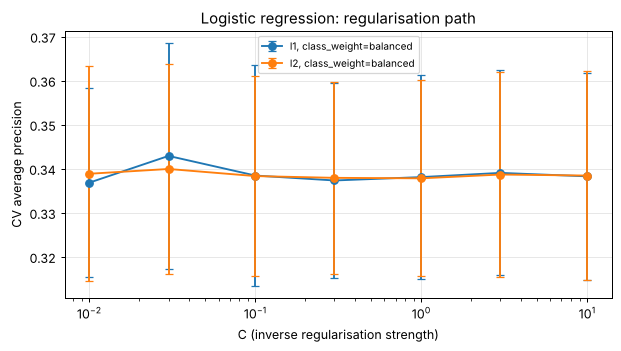

,avg_precision_mean,avg_precision_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,balanced_accuracy_mean,balanced_accuracy_std,precision_top10_mean,precision_top10_std
model,,,,,,,,,,,,,,
Dummy (stratified),0.1535,0.0013,0.4871,0.0075,0.1359,0.0125,0.1348,0.0124,0.1370,0.0127,0.4871,0.0075,0.1497,0.0099
Rule: PageValues > 0 (reference only),0.6219,0.0150,0.8621,0.0107,0.6617,0.0223,0.5620,0.0244,0.8047,0.0202,0.8442,0.0134,0.7190,0.0156
LR original features,0.3388,0.0254,0.7497,0.0083,0.0647,0.0255,0.4917,0.1488,0.0347,0.0140,0.5142,0.0068,0.3867,0.0263
LR augmented features,0.3439,0.0260,0.7537,0.0084,0.0858,0.0247,0.5489,0.1514,0.0465,0.0134,0.5197,0.0078,0.3979,0.0187
LR augmented + balanced,0.3379,0.0249,0.7530,0.0087,0.3974,0.0086,0.2719,0.0074,0.7385,0.0199,0.6860,0.0090,0.3949,0.0238
LR augmented + balanced + PageValues (sensitivity),0.6647,0.0100,0.9194,0.0070,0.6528,0.0145,0.5430,0.0138,0.8191,0.0323,0.8457,0.0143,0.7056,0.0152
LR tuned (best grid params),0.3467,0.0259,0.7487,0.0092,0.0026,0.0036,0.3000,0.4472,0.0013,0.0018,0.5005,0.0009,0.4072,0.0242
LR tuned + PageValues (sensitivity),0.6838,0.0107,0.9171,0.0081,0.6086,0.0118,0.7036,0.0158,0.5367,0.0212,0.7474,0.0091,0.7231,0.0131


In [9]:
# CV average precision across values of C, for the L1 and L2 penalties
fig, ax = plt.subplots(figsize=(7, 4))
for (pen, cw), g in grid[grid["param_clf__penalty"].isin(["l1", "l2"])].groupby(
        ["param_clf__penalty", grid["param_clf__class_weight"].astype(str)]):
    g = g.sort_values("param_clf__C")
    ax.errorbar(g["param_clf__C"].astype(float), g["mean_test_avg_precision"], yerr=g["std_test_avg_precision"],
                marker="o", capsize=3, label=f"{pen}, class_weight={cw}")
ax.set_xscale("log"); ax.set_xlabel("C (inverse regularisation strength)"); ax.set_ylabel("CV average precision")
ax.set_title("Logistic regression: regularisation path"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "lr_regularisation_path.png", dpi=150); plt.show()

# Add the two tuned models to the CV comparison table
best_row = cv_summary("LR tuned (best grid params)", search.best_estimator_)
best_row_pv = cv_summary("LR tuned + PageValues (sensitivity)", search_pv.best_estimator_)
cv_table = pd.concat([cv_table, pd.DataFrame([best_row, best_row_pv]).set_index("model")])
cv_table.to_csv(OUT / "lr_cv_results.csv")
cv_table

The best setting is **elastic-net with C = 0.03 and l1_ratio = 0.5**, without class weighting. Its CV AP is **0.347 ± 0.026**, only slightly above the untuned 0.344, so the choice of penalty makes little difference on this data. Strong shrinkage works best, and the elastic-net sets 62 of the 84 coefficients to zero.

With `PageValues` included, the best setting is L2 with C = 0.03, and CV AP rises to **0.684 ± 0.011**.

At the default 0.5 threshold, the tuned model predicts almost no purchases (CV recall 0.1%). Its ranking is fine, but its probabilities seldom pass 0.5, so we choose a lower threshold next.

## 9 · Choosing the Decision Threshold

The threshold is chosen from out-of-fold predictions on the training set, so the test set plays no part. We pick the threshold that maximizes F1, and also report the cut-off that would flag the top 10% of sessions.

Max-F1 threshold: 0.203  (OOF precision 0.299, recall 0.600, F1 0.400)
Top-10% threshold: 0.301


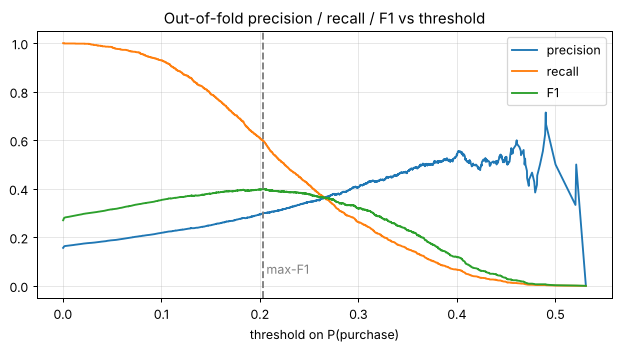

In [10]:
best_model = search.best_estimator_

# Out-of-fold probabilities: each training session is scored by a model that did not see it
oof = cross_val_predict(best_model, X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]

# F1 at every possible threshold; keep the threshold where it is highest
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
i = int(np.nanargmax(f1s))
THRESH_F1 = float(thr[i])

# Score cut-off that flags 10% of sessions
THRESH_TOP10 = float(np.quantile(oof, 0.90))
print(f"Max-F1 threshold: {THRESH_F1:.3f}  (OOF precision {prec[i]:.3f}, recall {rec[i]:.3f}, F1 {f1s[i]:.3f})")
print(f"Top-10% threshold: {THRESH_TOP10:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, prec[:-1], label="precision"); ax.plot(thr, rec[:-1], label="recall"); ax.plot(thr, f1s, label="F1")
ax.axvline(THRESH_F1, ls="--", c="grey"); ax.text(THRESH_F1, 0.05, " max-F1", color="grey")
ax.set_xlabel("threshold on P(purchase)"); ax.set_title("Out-of-fold precision / recall / F1 vs threshold")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(OUT / "lr_threshold_curve.png", dpi=150); plt.show()

F1 peaks at a threshold of **0.203**, with out-of-fold precision of 29.9%, recall of 60.0% and F1 of 0.400. Flagging the top 10% of sessions corresponds to a threshold of 0.301.

We use 0.203 for the test evaluation. With real costs (the cost of contacting a session and the value of a captured buyer), the threshold should instead maximize expected profit.

## 10 · Interpreting the Coefficients

Each coefficient is the change in the log-odds of purchase for a one-standard-deviation increase in the feature (after the log transform where applied), holding the other features fixed. `exp(coef)` is the odds ratio.

Non-zero coefficients: 22 of 84


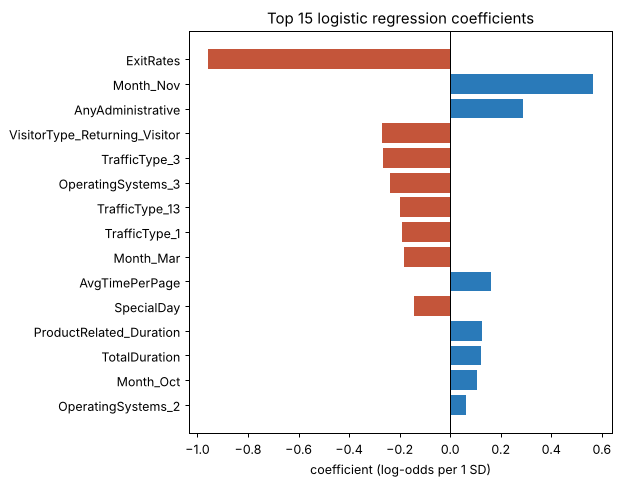

,feature,coef,odds_ratio
0,ExitRates,-0.9571,0.3840
1,Month_Nov,0.5645,1.7585
2,AnyAdministrative,0.2895,1.3357
3,VisitorType_Returning_Visitor,-0.2694,0.7638
4,TrafficType_3,-0.2644,0.7677
5,OperatingSystems_3,-0.2393,0.7872
6,TrafficType_13,-0.1994,0.8192
7,TrafficType_1,-0.1926,0.8248
8,Month_Mar,-0.1817,0.8338
9,AvgTimePerPage,0.1599,1.1734


In [11]:
# Match each coefficient to its column name after preprocessing
feat_names = best_model.named_steps["prep"].get_feature_names_out()
coefs = best_model.named_steps["clf"].coef_.ravel()

# Sort by absolute size; odds_ratio = exp(coef)
coef_df = (pd.DataFrame({"feature": feat_names, "coef": coefs, "odds_ratio": np.exp(coefs)})
             .assign(abs_coef=lambda d: d.coef.abs())
             .sort_values("abs_coef", ascending=False).drop(columns="abs_coef").reset_index(drop=True))
coef_df.to_csv(OUT / "lr_coefficients.csv", index=False)
print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}")

# Blue = higher purchase odds, red = lower purchase odds
top15 = coef_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top15.feature, top15.coef, color=np.where(top15.coef > 0, "#2a7ab9", "#c4553a"))
ax.axvline(0, c="black", lw=.8); ax.set_xlabel("coefficient (log-odds per 1 SD)")
ax.set_title("Top 15 logistic regression coefficients")
plt.tight_layout(); plt.savefig(OUT / "lr_top_coefficients.png", dpi=150); plt.show()
coef_df.head(15)

Only **22 of 84** coefficients are non-zero after regularization.

- **ExitRates** has by far the largest effect: a one-SD increase cuts the odds of purchase to **0.38×**.
- **November** sessions have **1.76×** the odds of purchase, in line with the EDA (25.4% conversion in November).
- Visiting **any administrative page** raises the odds to **1.34×**. Longer **time per page** and **product-page duration** have smaller positive effects (about 1.13–1.17×).
- **Returning visitors** have lower odds than average (**0.76×**), matching the EDA finding that new visitors convert more often (24.1% vs 14.2%).
- Several traffic types and operating system 3 are negative. These are anonymous codes, so we cannot say what they represent.

These are associations, not causal effects. Correlated features (such as the duration measures) share their effect, so individual coefficients should not be over-read.

## 11 · Evaluate on the Held-Out Test Set

The model and threshold are now fixed. The test set is used once, and the 95% intervals come from 1,000 bootstrap resamples of the test rows.

In [12]:
# Score the test set once with the fixed model and threshold
p_test = best_model.predict_proba(X_test)[:, 1]
yhat = (p_test >= THRESH_F1).astype(int)

rng = np.random.default_rng(RANDOM_STATE)

def boot_ci(fn, n=1000):
    """95% bootstrap interval: resample test rows with replacement and recompute the metric."""
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_test), len(y_test))
        if y_test[idx].min() == y_test[idx].max():  # skip samples that contain only one class
            continue
        vals.append(fn(y_test[idx], p_test[idx], yhat[idx]))
    return np.percentile(vals, [2.5, 97.5])

# Each metric takes (true labels, probabilities, 0/1 predictions)
metrics = {
    "Average precision": lambda y, p, h: average_precision_score(y, p),
    "ROC-AUC": lambda y, p, h: roc_auc_score(y, p),
    "F1 (max-F1 threshold)": lambda y, p, h: f1_score(y, h),
    "Precision (max-F1 threshold)": lambda y, p, h: precision_score(y, h),
    "Recall (max-F1 threshold)": lambda y, p, h: recall_score(y, h),
    "Accuracy (max-F1 threshold)": lambda y, p, h: accuracy_score(y, h),
    "Precision in top 10%": lambda y, p, h: precision_at_top(y, p),
}
test_rows = []
for name, fn in metrics.items():
    lo, hi = boot_ci(fn)
    test_rows.append({"metric": name, "test": fn(y_test, p_test, yhat), "ci95_low": lo, "ci95_high": hi})
test_table = pd.DataFrame(test_rows).set_index("metric")

# Lift = top-10% precision divided by the overall purchase rate
test_table.loc["Lift in top 10%"] = [test_table.loc["Precision in top 10%", "test"] / y_test.mean(), np.nan, np.nan]
test_table.to_csv(OUT / "lr_test_results.csv")
test_table

,test,ci95_low,ci95_high
metric,,,
Average precision,0.3467,0.3063,0.3946
ROC-AUC,0.7604,0.7377,0.7827
F1 (max-F1 threshold),0.4191,0.3842,0.4510
Precision (max-F1 threshold),0.3106,0.2791,0.3431
Recall (max-F1 threshold),0.6440,0.5968,0.6919
Accuracy (max-F1 threshold),0.7206,0.7009,0.7386
Precision in top 10%,0.4016,0.3443,0.4672
Lift in top 10%,2.5665,NaN,NaN


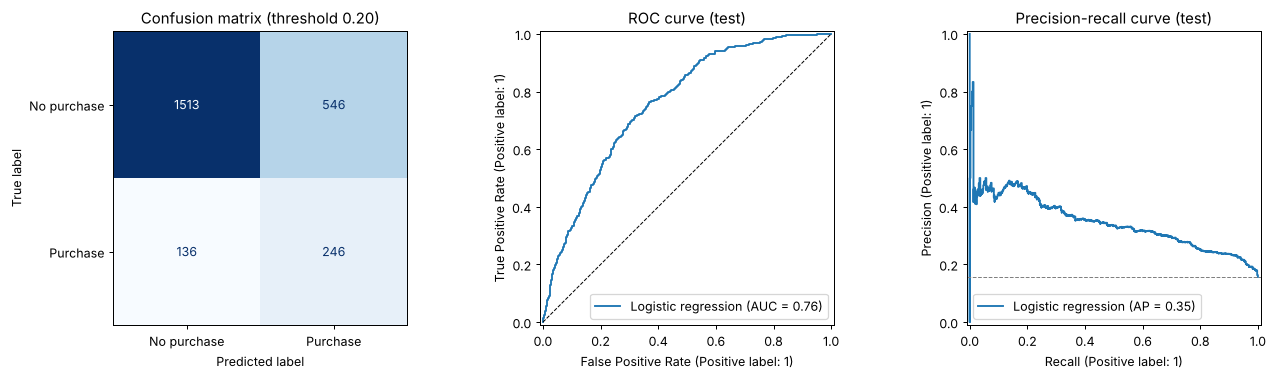

In [13]:
# Confusion matrix, ROC curve and precision-recall curve on the test set
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_test, yhat), display_labels=["No purchase", "Purchase"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title(f"Confusion matrix (threshold {THRESH_F1:.2f})")
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[1], name="Logistic regression")
axes[1].plot([0, 1], [0, 1], "k--", lw=.8); axes[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[2], name="Logistic regression")
axes[2].axhline(y_test.mean(), ls="--", c="grey", lw=.8); axes[2].set_title("Precision-recall curve (test)")  # grey line = purchase rate
plt.tight_layout(); plt.savefig(OUT / "lr_test_curves.png", dpi=150); plt.show()

| Metric | Test result | 95% bootstrap interval |
|---|---:|---|
| Average precision | 0.347 | 0.306–0.395 |
| ROC-AUC | 0.760 | 0.738–0.783 |
| Precision (threshold 0.203) | 31.1% | 27.9%–34.3% |
| Recall (threshold 0.203) | 64.4% | 59.7%–69.2% |
| F1 (threshold 0.203) | 0.419 | 0.384–0.451 |
| Precision in top 10% | 40.2% | 34.4%–46.7% |

Test AP (0.347) matches the CV estimate, so there is no sign of overfitting.

The model finds **246 of 382 buyers**, but also flags **546 non-buyers**. Among the 10% of sessions with the highest scores, **40.2%** purchase, which is **2.6 times** the base rate of 15.6%.

Accuracy (72.1%) is lower than the 84.4% from predicting that nobody buys. This is expected: the lower threshold gives up accuracy in exchange for catching more buyers.

## 12 · Comparison at the 0.5 Threshold, With and Without PageValues

The RF notebook reports test metrics at a fixed 0.5 threshold, so the same view is given here for both versions of the model.

In [14]:
def test_metric_row(model, threshold):
    """Test-set metrics in the same format as the RF notebook."""
    p = model.predict_proba(X_test)[:, 1]
    h = (p >= threshold).astype(int)
    return {"average_precision": average_precision_score(y_test, p), "roc_auc": roc_auc_score(y_test, p),
            "accuracy": accuracy_score(y_test, h), "balanced_accuracy": (recall_score(y_test, h) + recall_score(1 - y_test, 1 - h)) / 2,
            "precision": precision_score(y_test, h, zero_division=0), "recall": recall_score(y_test, h),
            "f1": f1_score(y_test, h), "precision_top10": precision_at_top(y_test, p),
            "tn_fp_fn_tp": confusion_matrix(y_test, h).ravel().tolist()}

# Max-F1 threshold for the PageValues model, chosen the same way as in section 9
oof_pv = cross_val_predict(search_pv.best_estimator_, X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
pr, rc, th = precision_recall_curve(y_train, oof_pv)
f1_pv = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
THRESH_F1_PV = float(th[int(np.nanargmax(f1_pv))])

compare = pd.DataFrame({
    "LR without PageValues @0.5": test_metric_row(best_model, 0.5),
    f"LR without PageValues @{THRESH_F1:.2f} (max-F1)": test_metric_row(best_model, THRESH_F1),
    "LR with PageValues @0.5": test_metric_row(search_pv.best_estimator_, 0.5),
    f"LR with PageValues @{THRESH_F1_PV:.2f} (max-F1)": test_metric_row(search_pv.best_estimator_, THRESH_F1_PV),
}).T
compare.to_csv(OUT / "lr_test_comparison_table.csv")
compare

,average_precision,roc_auc,accuracy,balanced_accuracy,precision,recall,f1,precision_top10,tn_fp_fn_tp
LR without PageValues @0.5,0.3467,0.7604,0.8439,0.5024,0.6667,0.0052,0.0104,0.4016,"[2058, 1, 380, 2]"
LR without PageValues @0.20 (max-F1),0.3467,0.7604,0.7206,0.6894,0.3106,0.6440,0.4191,0.4016,"[1513, 546, 136, 246]"
LR with PageValues @0.5,0.6990,0.9251,0.8959,0.7667,0.7038,0.5785,0.6351,0.7582,"[1966, 93, 161, 221]"
LR with PageValues @0.24 (max-F1),0.6990,0.9251,0.8873,0.8309,0.6151,0.7487,0.6753,0.7582,"[1880, 179, 96, 286]"


- **Without PageValues at 0.5**, the model predicts only 3 purchases and recall is 0.5%. Its AP and ROC-AUC are the same as at 0.203, which shows the problem is the threshold, not the ranking.
- **With PageValues**, test AP rises to **0.699** and ROC-AUC to **0.925**. At 0.5 it reaches precision of 70.4%, recall of 57.9% and F1 of 0.635. At its own max-F1 threshold (0.24), F1 is 0.675.

Because F1, precision and recall depend on the threshold, average precision and ROC-AUC are the fairest metrics for comparing models.

## 13 · Save the Model

In [15]:
# Save both fitted pipelines with their thresholds
joblib.dump({"pipeline": search_pv.best_estimator_, "threshold_max_f1": THRESH_F1_PV},
            MODEL_DIR / "logistic_regression_with_pagevalues.joblib")
joblib.dump({"pipeline": best_model, "threshold_max_f1": THRESH_F1, "threshold_top10": THRESH_TOP10,
             "feature_engineering": "add_features() in this notebook", "excluded": ["PageValues", "source_row_id"]},
            MODEL_DIR / "logistic_regression.joblib")

# Out-of-fold training probabilities, for comparing or combining models on the same folds
pd.DataFrame({"source_row_id": X_train.get("source_row_id", pd.Series(range(len(X_train)))).values,
              "y": y_train, "lr_oof_proba": oof}).to_csv(OUT / "lr_oof_predictions.csv", index=False)
print(f"Saved models and results to {OUT}/")

Saved models and results to logistic_regression_results/


## 14 · Summary

- Without `PageValues`, logistic regression reaches a test AP of **0.347** and ROC-AUC of **0.760**, more than double the AP of random ranking (0.156).
- Its 10% highest-scored sessions convert at **40.2%**, 2.6 times the base rate, which is useful for prioritizing a limited marketing budget.
- The strongest signals are a low exit rate, November sessions, administrative page visits and new visitors.
- Adding `PageValues` raises test AP to **0.699**, so this one column drives much of the predictive power. Whether it should be used depends on whether it is available before a purchase.
- As a linear model, logistic regression cannot capture interactions between features; the tree-based models are compared against it on the same folds.